# Week 4 Lab: The Inverse Fourier Transform and Negative Frequencies

**Course:** Brain-Computer Interfacing

Each part has a solved example, then a practice task that is very close to the example. Read the example, run it, then copy and adapt it for the practice.

---

## Setup

Last week we went **from a signal to its waves** (the Fourier coefficients). This week we finish the story:

- Part 1: the **inverse** Fourier transform: from the waves back to the signal.
- Part 2: **negative frequencies**: why the spectrum of a real signal is a mirror.
- Part 3: keep only some frequencies: **compression**, **denoising** and **filtering** real EEG.

In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

plt.style.use('dark_background')
np.random.seed(42)

---

## Part 1: The Inverse Fourier Transform

### Example 1a: rotate the arrows and add them

Reminder from Week 3: each Fourier coefficient `c[fi]` is an arrow. Its length and angle tell how big the wave at frequency `fi` is and where it **starts**.

To get the signal back:

1. Let every arrow **spin** again at its own speed: `c[fi] · e^{+i2π·fi·t}` (plus sign this time: we are not "stopping" it any more).
2. **Add** all the spinning arrows together.

That's it: the Fourier transform finds the starting arrows, the inverse sets them spinning and adds them up. Nothing is lost on the way.

We use the same test signal as Week 3, so we know what to expect: `1 + 2·sin(2π·4t) + 1·cos(2π·10t + π/4)`.

largest imaginary part: 5.7e-14  (a real signal stays real)
real part equals the signal: True
same as np.fft.ifft(coefs * N): True


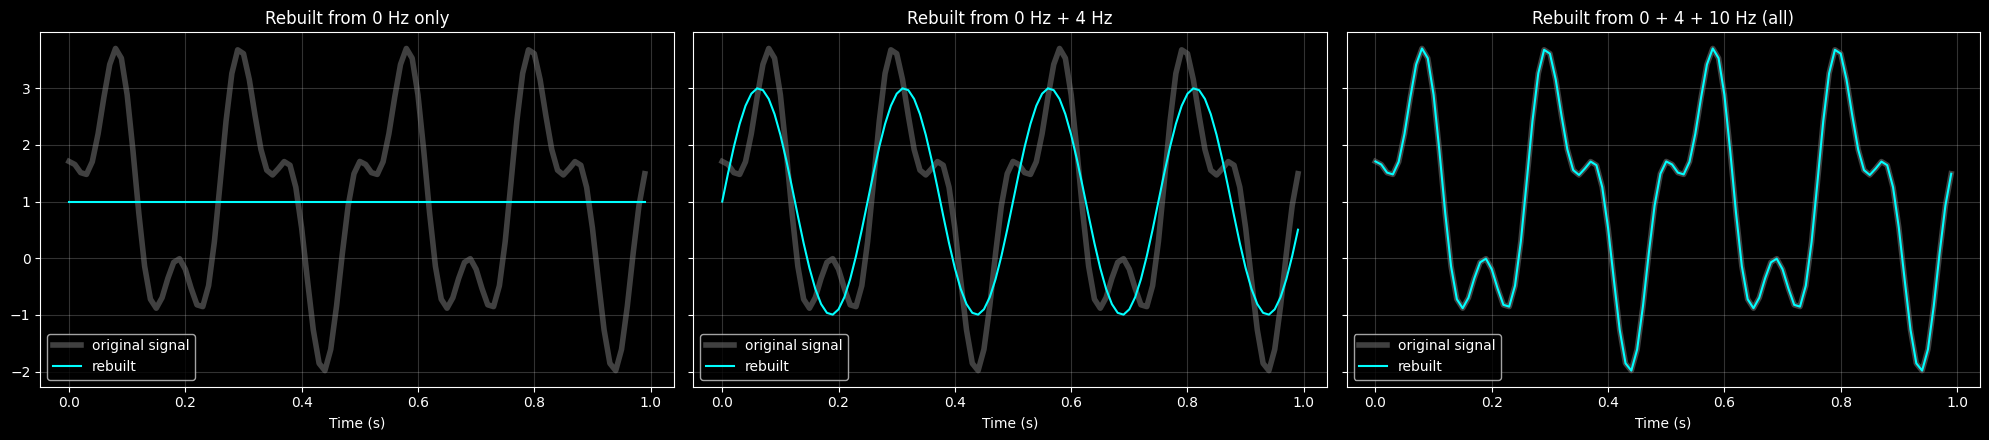

In [2]:
fs = 100
t = np.arange(0, 1, 1 / fs)
signal = 1 + 2 * np.sin(2 * np.pi * 4 * t) + 1 * np.cos(2 * np.pi * 10 * t + np.pi / 4)

N = len(signal)
four_time = np.arange(N) / N
coefs = np.zeros(N, dtype=complex)
for fi in range(N):                                   # forward transform (Week 3)
    coefs[fi] = np.sum(signal * np.exp(-1j * 2 * np.pi * fi * four_time)) / N

recon = np.zeros(N, dtype=complex)
for fi in range(N):                                   # inverse: spin every arrow and add
    recon += coefs[fi] * np.exp(1j * 2 * np.pi * fi * four_time)

print(f"largest imaginary part: {np.abs(recon.imag).max():.1e}  (a real signal stays real)")
print(f"real part equals the signal: {np.allclose(recon.real, signal)}")
print(f"same as np.fft.ifft(coefs * N): {np.allclose(recon, np.fft.ifft(coefs * N))}")

steps = [('0 Hz only', [0]), ('0 Hz + 4 Hz', [0, 4]), ('0 + 4 + 10 Hz (all)', [0, 4, 10])]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5), sharey=True)
for ax, (title, keep) in zip(axes, steps):
    idx = sorted({k for f0 in keep for k in (f0, (N - f0) % N)})     # each frequency and its mirror (Part 2)
    part = sum(coefs[k] * np.exp(1j * 2 * np.pi * k * four_time) for k in idx)
    ax.plot(t, signal, color='gray', linewidth=4, alpha=0.5, label='original signal')
    ax.plot(t, part.real, color='cyan', linewidth=1.5, label='rebuilt')
    ax.set_title(f'Rebuilt from {title}')
    ax.set_xlabel('Time (s)')
    ax.legend(loc='lower left')
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

Adding the waves one by one: first the constant (a flat line at 1), then the 4 Hz wave on top, then the 10 Hz wave. With all of them, the rebuilt signal lies exactly on the original.

`np.fft.ifft` is the fast inverse. Because our forward transform divided by `N` (to get real amplitudes), we multiply by `N` before calling `np.fft.ifft`.

### Example 1b: the arrows drawing the signal

At one moment in time, take **all** the arrows, put them tip to tail, and look where the last tip ends. Its real part (x position) is the value of the signal at that moment. Move to the next moment, every arrow turns a bit, and the tip lands on the next value of the signal.

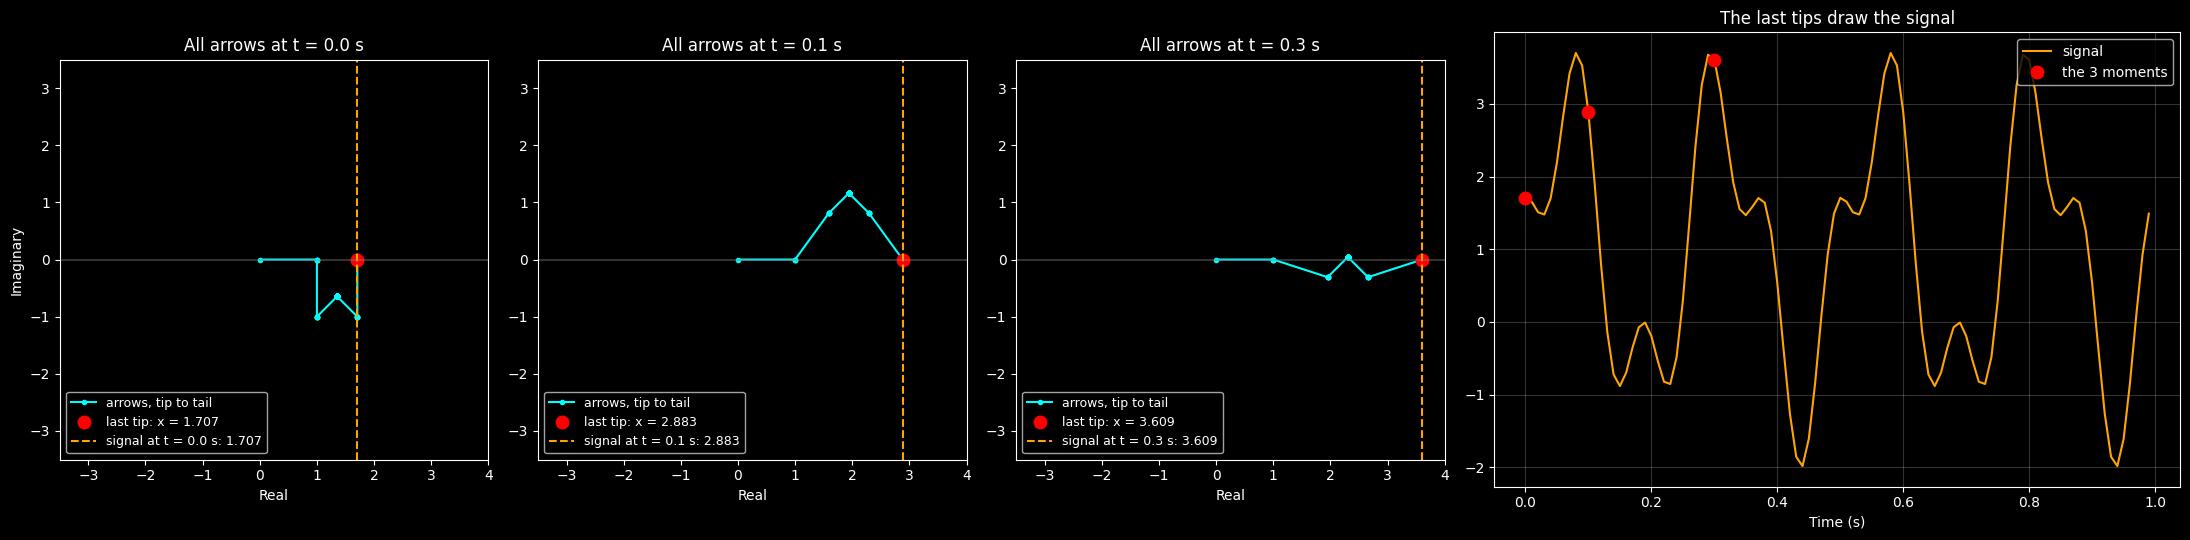

In [3]:
moments = [0, 10, 30]                                # sample numbers: t = 0, 0.1, 0.3 s
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), gridspec_kw={'width_ratios': [1, 1, 1, 1.6]})
for ax, k in zip(axes[:3], moments):
    vectors = coefs * np.exp(1j * 2 * np.pi * np.arange(N) * k / N)    # all arrows at time sample k
    tips = np.concatenate([[0], np.cumsum(vectors)])                    # tip to tail
    ax.plot(tips.real, tips.imag, '-o', color='cyan', markersize=3, linewidth=1.5, label='arrows, tip to tail')
    ax.plot(tips[-1].real, tips[-1].imag, 'o', color='red', markersize=9, label=f'last tip: x = {tips[-1].real:.3f}')
    ax.axvline(signal[k], color='orange', linestyle='--', label=f'signal at t = {t[k]:.1f} s: {signal[k]:.3f}')
    ax.axhline(0, color='gray', alpha=0.4)
    ax.set_aspect('equal')
    ax.set_xlim(-3.5, 4)
    ax.set_ylim(-3.5, 3.5)
    ax.set_xlabel('Real')
    ax.set_title(f'All arrows at t = {t[k]:.1f} s')
    ax.legend(loc='lower left', fontsize=9)
axes[0].set_ylabel('Imaginary')
axes[3].plot(t, signal, color='orange', linewidth=1.5, label='signal')
axes[3].plot(t[moments], signal[moments], 'o', color='red', markersize=9, label='the 3 moments')
axes[3].set_xlabel('Time (s)')
axes[3].set_title('The last tips draw the signal')
axes[3].legend(loc='upper right')
axes[3].grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

Only a few arrows are visible (0 Hz, 4 Hz, 10 Hz and their mirrors); the other 95 have length 0. The last tip always lands on the horizontal axis, exactly at the value of the signal. Why it never leaves the axis is the topic of Part 2.

### Practice 1 (10 min)

The `mystery` signal from Week 3 and its Fourier coefficients `coefs_m` are given.

1. `four_time_m`: normalized time `0, 1/N_m, ..., (N_m − 1)/N_m`.
2. `recon_m`: the inverse Fourier transform with the **loop** of Example 1a. Keep only the real part.
3. `recon_fft`: the same with `np.fft.ifft` (real part). Remember the `× N_m`.
4. `max_error`: the largest absolute difference between `mystery` and `recon_m`.

In [4]:
rng = np.random.default_rng(7)
fs_m = 200
t_m = np.arange(0, 2, 1 / fs_m)
mystery = (0.5 + 1.5 * np.cos(2 * np.pi * 6 * t_m + 1.0) + 0.8 * np.sin(2 * np.pi * 22 * t_m)
           + 0.3 * rng.standard_normal(len(t_m)))
N_m = len(mystery)
coefs_m = np.fft.fft(mystery) / N_m                   # Fourier coefficients, divided by N as in Week 3
print(f"mystery: {mystery.shape}, coefs_m: {coefs_m.shape}")

mystery: (400,), coefs_m: (400,)


largest error: 8.88e-16


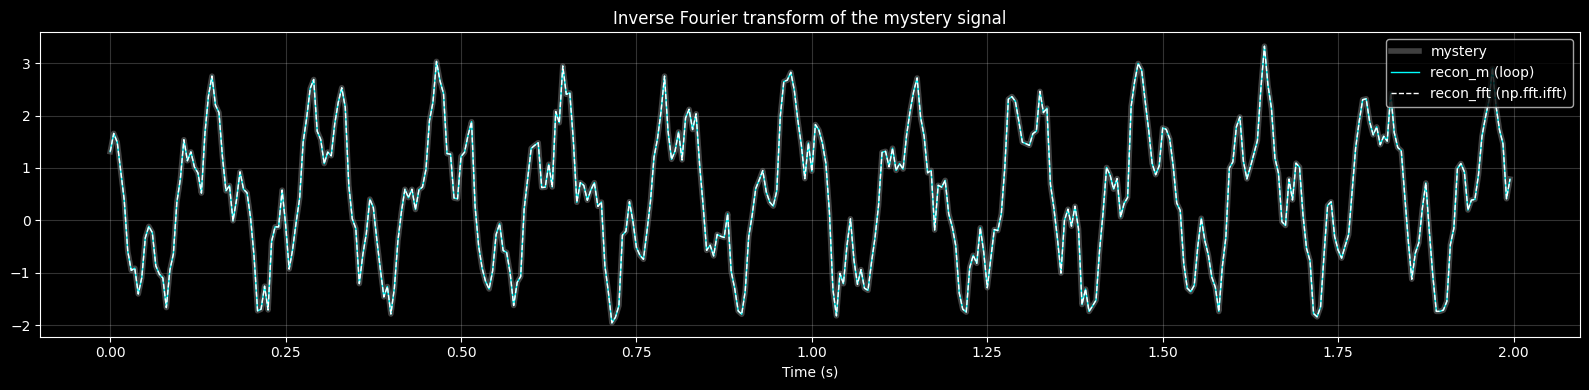

In [14]:
# YOUR CODE HERE
four_time_m = np.arange(N_m) / N_m

recon_m = 0
for fi in range(N_m):                                   # inverse: spin every arrow and add
    recon_m += coefs_m[fi] * np.exp(1j * 2 * np.pi * fi * four_time_m)
recon_m = recon_m.real

recon_fft = np.fft.ifft(coefs_m * N_m).real

max_error = np.abs(mystery - recon_fft.real).max()

print(f"largest error: {max_error:.2e}")
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(t_m, mystery, color='gray', linewidth=4, alpha=0.5, label='mystery')
ax.plot(t_m, recon_m, color='cyan', linewidth=1, label='recon_m (loop)')
ax.plot(t_m, recon_fft, color='white', linewidth=1, linestyle='--', label='recon_fft (np.fft.ifft)')
ax.set_xlabel('Time (s)')
ax.set_title('Inverse Fourier transform of the mystery signal')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [15]:
# Tests
assert np.allclose(four_time_m, np.arange(400) / 400), "four_time_m: 0, 1/N, ..., (N-1)/N"
assert np.shape(recon_m) == (400,) and np.isrealobj(recon_m) and np.allclose(recon_m, mystery), "recon_m: real part of the loop inverse"
assert np.isrealobj(recon_fft) and np.allclose(recon_fft, mystery), "recon_fft: np.fft.ifft(coefs_m * N_m).real"
assert np.isclose(max_error, np.abs(mystery - np.fft.ifft(coefs_m * N_m).real).max(), atol=1e-12) and max_error < 1e-9, "max_error: largest |mystery - recon_m|"
print("Practice 1 passed.")


Practice 1 passed.


---

## Part 2: Negative Frequencies

### Example 2a: the mirror arrows

In Week 3 the spectrum of a real signal looked like a mirror: index `N − k` had the same height as index `k`. Now we can see why.

- `e^{i2π·96·t}` with `N = 100` turns 96 times per window. That looks exactly like turning **4 times backwards**: index 96 is really **−4 Hz**. Indices above `N/2` are the **negative frequencies**.
- For a real signal, `c[N − k]` is the **mirror** of `c[k]`: same length, opposite angle (the *complex conjugate*).
- So every wave is made of **two arrows** of half the size, spinning in **opposite** directions. Their up/down (imaginary) parts always cancel, so their sum stays on the real axis. That is why the signal stays real, and why we doubled the amplitudes in Week 3.

In [ ]:
print(f"c[4]  = {coefs[4]:.3f}    c[96] = {coefs[96]:.3f}")
print(f"c[10] = {coefs[10]:.3f}    c[90] = {coefs[90]:.3f}")
print(f"every c[N−k] is the mirror (conjugate) of c[k]: {np.allclose(coefs[1:], np.conj(coefs[1:][::-1]))}")

circle = np.linspace(0, 2 * np.pi, 400)
arrow = dict(angles='xy', scale_units='xy', scale=1, width=0.012)
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, k in zip(axes, [0, 5, 10, 15]):                   # t = 0, 0.05, 0.10, 0.15 s
    a = coefs[4] * np.exp(1j * 2 * np.pi * 4 * k / N)      # +4 Hz arrow
    b = coefs[96] * np.exp(1j * 2 * np.pi * 96 * k / N)    # index 96 = −4 Hz arrow
    for radius in [1, 2]:
        ax.plot(radius * np.cos(circle), radius * np.sin(circle), color='gray', linestyle=':', linewidth=1)
    ax.quiver(0, 0, a.real, a.imag, color='cyan', label='+4 Hz arrow', **arrow)
    ax.quiver(a.real, a.imag, b.real, b.imag, color='orange', label='−4 Hz arrow (tip to tail)', **arrow)
    ax.quiver(0, 0, (a + b).real, (a + b).imag, color='lime', label=f'sum = {(a + b).real:+.2f}', **arrow)
    ax.axhline(0, color='gray', alpha=0.4)
    ax.set_aspect('equal')
    ax.set_xlim(-2.3, 2.3)
    ax.set_ylim(-2.3, 2.3)
    ax.set_xlabel('Real')
    ax.set_title(f't = {t[k]:.2f} s')
    ax.legend(loc='lower left', fontsize=9)
axes[0].set_ylabel('Imaginary')
plt.tight_layout()
plt.show()

`c[4] = −1j` and `c[96] = +1j`: same length (1), opposite angles. As time goes on, the cyan arrow turns one way and the orange arrow the other way. The green sum only moves left and right on the real axis, between −2 and +2: that is the 4 Hz wave with amplitude 2.

### Example 2b: a complex signal has no mirror

The transcript ends with a **complex** signal: `z(t) = 3·cos(2π·5t) + i·3·sin(2π·5t) = 3·e^{i2π·5t}`. This is **one** arrow of length 3 spinning forward at 5 Hz, so its spectrum has **one** spike, at +5 Hz, and no mirror.

A real cosine is different: `cos θ = (e^{iθ} + e^{−iθ}) / 2`. It needs **two** arrows of half the length, at +5 Hz and −5 Hz.

In [ ]:
z = 3 * np.exp(1j * 2 * np.pi * 5 * t)               # complex: 3·cos + i·3·sin
x_real = 3 * np.cos(2 * np.pi * 5 * t)               # real: 3·cos only
coefs_z = np.fft.fft(z) / N
coefs_x = np.fft.fft(x_real) / N
for name, cz in [('complex z', coefs_z), ('real 3·cos', coefs_x)]:
    nz = np.flatnonzero(np.abs(cz) > 1e-9)
    print(f"{name:<11}: non-zero indices {nz}, lengths {np.round(np.abs(cz[nz]), 3)}")

fig = plt.figure(figsize=(22, 5))
ax0 = fig.add_subplot(1, 3, 1, projection='3d')
ax0.plot(t, z.real, z.imag, color='white')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Real (3·cos)')
ax0.set_zlabel('Imaginary (3·sin)')
ax0.set_title('Complex signal z(t): a helix of radius 3')
for i, (name, cz, color) in enumerate([('complex z', coefs_z, 'cyan'), ('real 3·cos', coefs_x, 'orange')]):
    ax = fig.add_subplot(1, 3, i + 2)
    ax.stem(np.arange(N), np.abs(cz), linefmt=color, markerfmt='o', basefmt=' ')
    ax.axvline(N / 2, color='red', linestyle='--', alpha=0.6, label='N / 2: after this, negative frequencies')
    ax.set_ylim(0, 3.3)
    ax.set_xlabel('Frequency index fi')
    ax.set_ylabel('|c|')
    ax.set_title(f'Spectrum of {name}')
    ax.legend(loc='upper center', fontsize=9)
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

- Complex `z`: one spike of length 3 at index 5 (+5 Hz).
- Real `3·cos`: two spikes of length 1.5, at index 5 (+5 Hz) and index 95 (−5 Hz). 1.5 + 1.5 = 3: that's why we multiply by 2 when we show only the positive half.

EEG is a real signal, so its spectrum is always a mirror, and we only need to look at the positive half.

---

## Part 3: Keeping Only Some Frequencies

The transcript mentions that videos and images are compressed in the frequency domain. The idea: go to the frequency domain, **keep only the important coefficients** (set the others to zero), and go back with the inverse transform.

### Example 3a: compression and denoising

The `mystery` signal has 400 samples, so 400 coefficients. Most of them are only noise. Let's keep only the **5 biggest** ones.

kept frequencies (Hz): [-22.  -6.   0.   6.  22.]
numbers stored: 5 of 400
error vs the noise-free signal: noisy 0.279, 5 coefficients 0.042  (RMS)


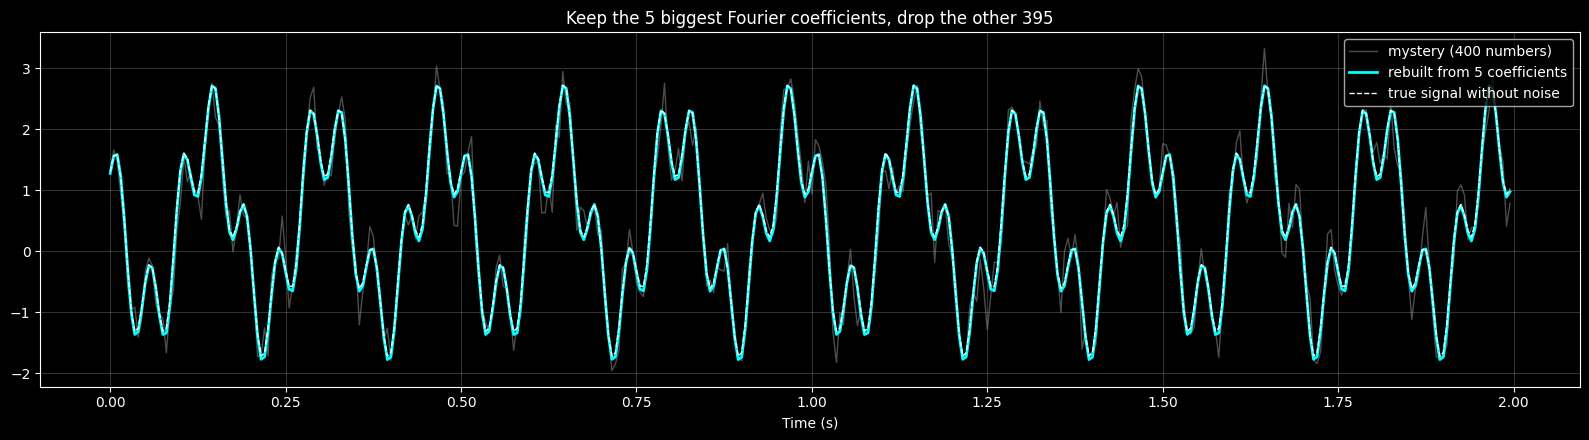

In [16]:
keep = 5
biggest = np.argsort(np.abs(coefs_m))[::-1][:keep]      # indices of the 5 longest arrows
mask = np.zeros(N_m, dtype=bool)
mask[biggest] = True
compressed = np.fft.ifft(coefs_m * mask * N_m).real

clean_truth = 0.5 + 1.5 * np.cos(2 * np.pi * 6 * t_m + 1.0) + 0.8 * np.sin(2 * np.pi * 22 * t_m)
freqs_m = np.fft.fftfreq(N_m, 1 / fs_m)                   # frequency of every index, negative ones included
print(f"kept frequencies (Hz): {np.sort(freqs_m[mask])}")
print(f"numbers stored: {keep} of {N_m}")
print(f"error vs the noise-free signal: noisy {np.sqrt(np.mean((mystery - clean_truth)**2)):.3f}, "
      f"5 coefficients {np.sqrt(np.mean((compressed - clean_truth)**2)):.3f}  (RMS)")

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(t_m, mystery, color='gray', alpha=0.6, linewidth=1, label='mystery (400 numbers)')
ax.plot(t_m, compressed, color='cyan', linewidth=2, label=f'rebuilt from {keep} coefficients')
ax.plot(t_m, clean_truth, color='white', linestyle='--', linewidth=1, label='true signal without noise')
ax.set_xlabel('Time (s)')
ax.set_title('Keep the 5 biggest Fourier coefficients, drop the other 395')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

The 5 coefficients are 0 Hz, ±6 Hz and ±22 Hz: the constant and the two hidden waves (each with its mirror). With only 5 numbers instead of 400 we rebuild the signal **and** the noise is gone, because noise is spread thinly over all frequencies.

### Example 3b: filtering EEG with the Fourier transform

Same EEG data as Weeks 2 and 3 (left/right hand imagery, C3 / Cz / C4, 128 Hz, 140 trials of 9 s).

To keep only the **mu band (8 – 12 Hz)**: take the FFT, set every coefficient outside 8 – 12 Hz to zero (on **both** the positive and the negative side, so the result stays real), and take the inverse FFT. This is a **band-pass filter**.

X: (140, 3, 1152), frequency step 0.111 Hz, kept 74 of 1152 coefficients


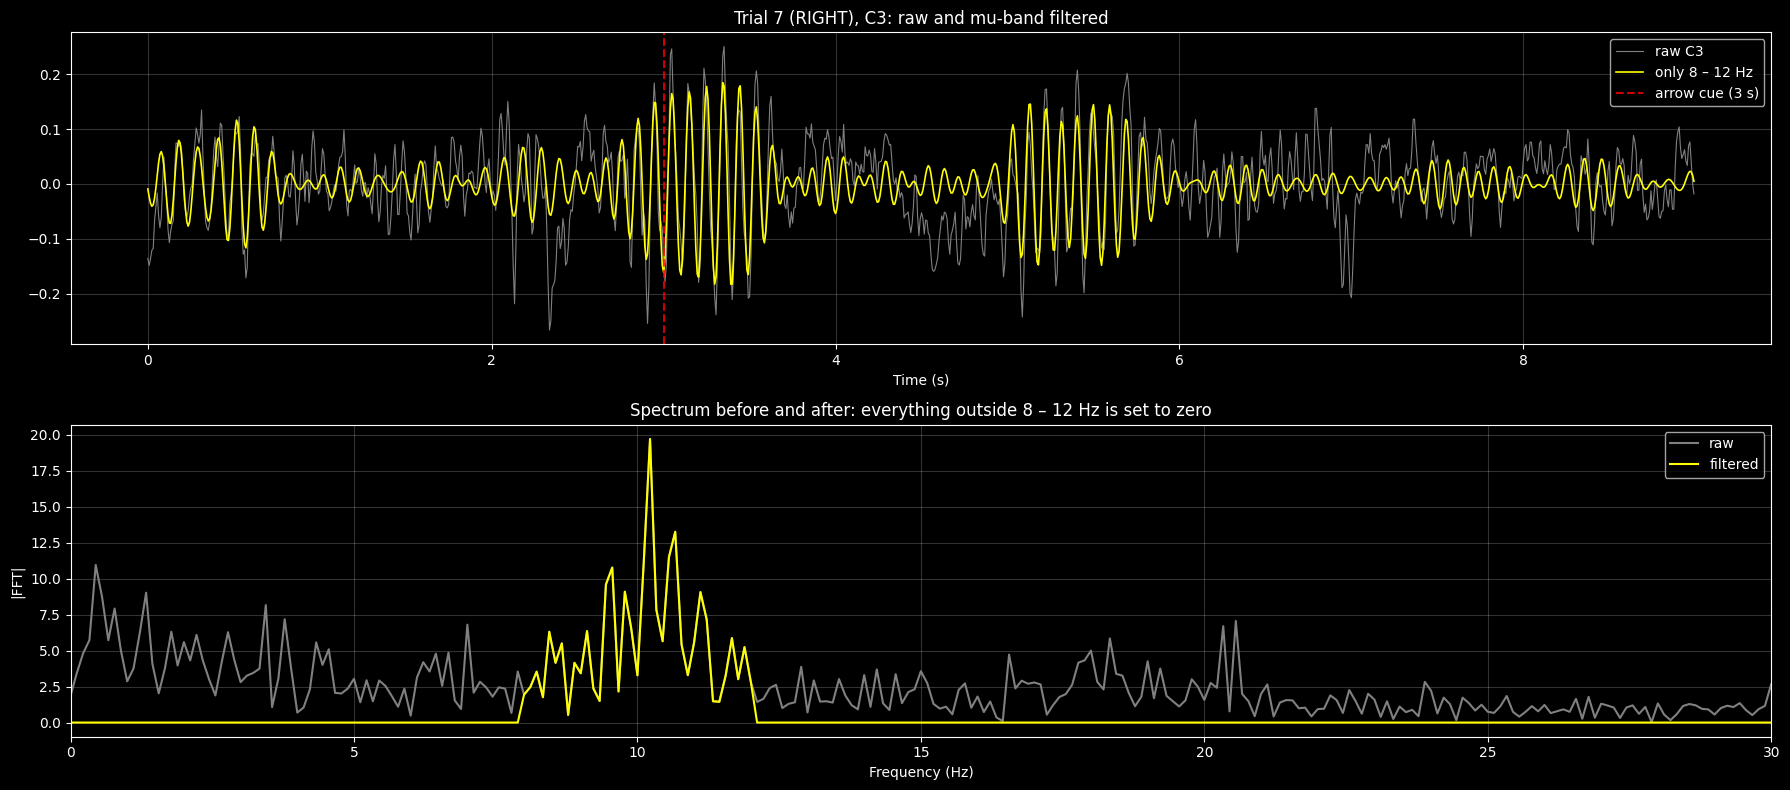

In [17]:
DATA_FILE = 'dataset_BCIcomp1.mat'
DATA_URL = 'https://raw.githubusercontent.com/bhoom10/bci-media-player/master/dataset_BCIcomp1.mat'
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

mat = loadmat(DATA_FILE)
X = np.transpose(mat['x_train'], (2, 1, 0))      # (trials, channels, time)
y = mat['y_train'].ravel()

fs = 128
channel_names = ['C3', 'Cz', 'C4']
class_names = {1: 'LEFT', 2: 'RIGHT'}
class_colors = {1: 'cyan', 2: 'orange'}
n_trials, n_channels, n_times = X.shape
times = np.arange(n_times) / fs

freqs = np.fft.fftfreq(n_times, 1 / fs)          # 0, +0.11, ..., +64, then the negative frequencies
mu_mask = (np.abs(freqs) >= 8) & (np.abs(freqs) <= 12)

trial = 7
raw = X[trial, 0]
raw_mu = np.fft.ifft(np.fft.fft(raw) * mu_mask).real
print(f"X: {X.shape}, frequency step {freqs[1]:.3f} Hz, kept {mu_mask.sum()} of {n_times} coefficients")

fig, axes = plt.subplots(2, 1, figsize=(18, 8))
axes[0].plot(times, raw, color='gray', linewidth=0.8, label='raw C3')
axes[0].plot(times, raw_mu, color='yellow', linewidth=1.2, label='only 8 – 12 Hz')
axes[0].axvline(3, color='red', linestyle='--', alpha=0.8, label='arrow cue (3 s)')
axes[0].set_xlabel('Time (s)')
axes[0].set_title(f'Trial {trial} ({class_names[y[trial]]}), C3: raw and mu-band filtered')
axes[0].legend(loc='upper right')
half = freqs >= 0
axes[1].plot(freqs[half], np.abs(np.fft.fft(raw))[half], color='gray', label='raw')
axes[1].plot(freqs[half], np.abs(np.fft.fft(raw_mu))[half], color='yellow', label='filtered')
axes[1].set_xlim(0, 30)
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('|FFT|')
axes[1].set_title('Spectrum before and after: everything outside 8 – 12 Hz is set to zero')
axes[1].legend(loc='upper right')
for ax in axes:
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

The yellow signal is the mu rhythm alone. Its size goes up and down over time: that is what we want to follow. Squaring it gives the **mu power at every moment**.

### Practice 2 (12 min)

When exactly does the mu power drop? Filter **all** trials and channels at once, then average the power over the trials of each class.

1. `X_mu`: every trial and channel of `X` filtered to 8 – 12 Hz with `mu_mask` (FFT along the last axis, multiply, inverse FFT, real part). Shape (140, 3, 1152).
2. `mu_power_t`: shape (2, 3, 1152). Row 0: the mean of `X_mu ** 2` over the LEFT trials; row 1: over the RIGHT trials.

The plot then smooths the power (0.5 s moving average) and shows it as a percent change from the rest period (0.5 – 2 s).

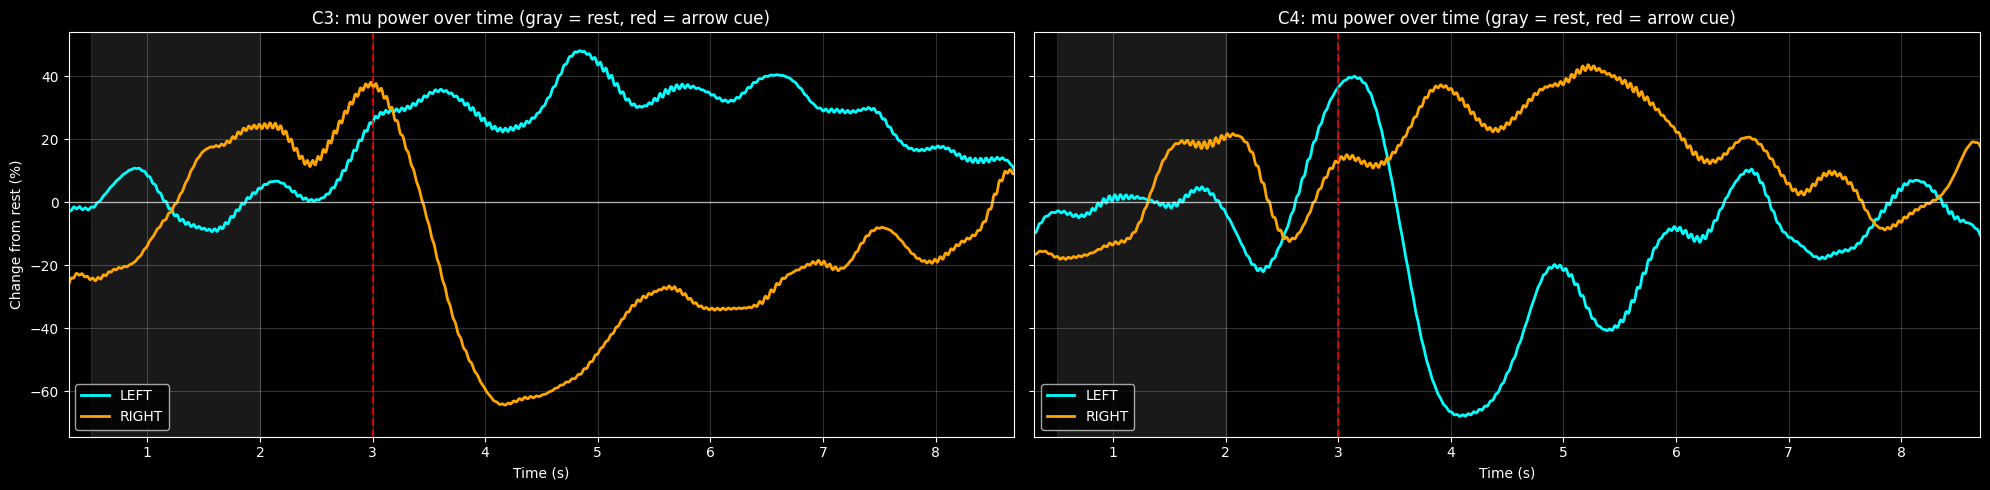

In [19]:
# YOUR CODE HERE
X_mu = np.fft.fft(np.fft.ifft(X) * mu_mask, axis= -1).real

mu_power_t = np.array(
    [
        np.mean(X_mu[y == 1] ** 2, axis = 0),
        np.mean(X_mu[y == 2] ** 2, axis = 0)
    ]
)


smooth = np.ones(fs // 2) / (fs // 2)                    # 0.5 s moving average
base = (times >= 0.5) & (times < 2)
fig, axes = plt.subplots(1, 2, figsize=(20, 5), sharey=True)
for ax, c in zip(axes, [0, 2]):
    for row, label in enumerate([1, 2]):
        p = np.convolve(mu_power_t[row, c], smooth, mode='same')
        p = 100 * (p - p[base].mean()) / p[base].mean()
        ax.plot(times, p, color=class_colors[label], linewidth=2, label=class_names[label])
    ax.axhline(0, color='white', linewidth=1, alpha=0.6)
    ax.axvspan(0.5, 2, color='gray', alpha=0.2)
    ax.axvline(3, color='red', linestyle='--', alpha=0.8)
    ax.set_xlim(0.3, 8.7)
    ax.set_xlabel('Time (s)')
    ax.set_title(f'{channel_names[c]}: mu power over time (gray = rest, red = arrow cue)')
    ax.legend(loc='lower left')
    ax.grid(True, alpha=0.2)
axes[0].set_ylabel('Change from rest (%)')
plt.tight_layout()
plt.show()

In [20]:
# Tests
_xm = np.fft.ifft(np.fft.fft(X, axis=-1) * mu_mask, axis=-1).real
assert np.shape(X_mu) == (140, 3, 1152) and np.isrealobj(X_mu) and np.allclose(X_mu, _xm), "X_mu: ifft(fft(X) * mu_mask).real along the last axis"
assert np.shape(mu_power_t) == (2, 3, 1152), "mu_power_t: shape (2, 3, 1152)"
assert np.allclose(mu_power_t[0], (_xm[y == 1] ** 2).mean(axis=0)), "mu_power_t[0]: mean power of the LEFT trials"
assert np.allclose(mu_power_t[1], (_xm[y == 2] ** 2).mean(axis=0)), "mu_power_t[1]: mean power of the RIGHT trials"
print("Practice 2 passed.")


Practice 2 passed.


Week 3 gave one number per window. Now we see the mu power **over time**: around 0 % during rest, then about 1 s after the arrow cue it drops by roughly 50 – 60 % on the side opposite to the imagined hand (RIGHT at C3, LEFT at C4), while it goes **up** on the same side. The lines are noisy because each point is an average over only 70 trials.

---

## Summary

- **Inverse Fourier transform:** let every coefficient spin at its own frequency (`e^{+i2π·fi·t}`) and add them. `np.fft.ifft` does it fast (multiply by `N` if the forward transform was divided by `N`). Nothing is lost.
- At every moment, the arrows tip to tail end exactly at the value of the signal.
- **Negative frequencies:** indices above `N/2` spin backwards. For a real signal `c[N − k]` is the mirror of `c[k]`, so each wave is two half-size arrows spinning in opposite directions. A complex signal like `3·e^{i2π·5t}` has only one arrow and no mirror.
- **Keeping only some coefficients:** a few big coefficients can rebuild a signal (**compression**, **denoising**). Keeping a frequency band and going back is a **band-pass filter**: on EEG, it lets us follow the mu power over time.